# 04 · Parent–child repertoire decay

How much of its parent's ligand repertoire a node keeps, against the length of the branch
between them, for every parent–child edge of the human tree: ancestor to ancestor and
ancestor to extant receptor. Writes `results/edge_table.csv` (Fig. 3f, Extended Data
Fig. 5d), `results/decay_fit.csv` and `results/threshold_sweep.csv`.

In [1]:
import os
import sys
from pathlib import Path

REPO = Path("../..").resolve()
sys.path.append(str(REPO / "Downstream_Analysis/scripts"))
sys.path.append(str(REPO / "scripts"))

from ancestral_sets import ASR_MATRIX, REF_MATRIX, PAIRS, FASTA, ASR_TREE, FIGURES, TABLES

INPUTS = [ASR_MATRIX, REF_MATRIX, PAIRS, FASTA, ASR_TREE]
TABLES_WRITTEN = ["edge_table", "decay_fit", "threshold_sweep"]
FIGURES_WRITTEN = ["threshold_check"]

for path in INPUTS:
    print("input  ", os.path.relpath(path, REPO))
print("tables ", os.path.relpath(TABLES, REPO), TABLES_WRITTEN)
print("figures", os.path.relpath(FIGURES, REPO), FIGURES_WRITTEN)

input   Downstream_Analysis/predictions/aggregated/ASR_Predictions/asr_median_probability_wide.csv
input   Downstream_Analysis/predictions/aggregated/Reference_Tree_Predictions/reference_median_probability_wide.csv
input   Model_Inputs/Data_Preparation/processed/m2or_pairs_model.csv
input   Phylogenetic_Analysis/data/ReferenceTree/PF13853.9606_7955_7740_7764_75743_137246.fa
input   Ancestral_Receptor_Reconstruction/human_tree_asr_hagfish_outgroup/PF13853_9606.7764.mafft.lg.treefile.rooted.withinternalnames
tables  Downstream_Analysis/ancestral_receptors/results ['edge_table', 'decay_fit', 'threshold_sweep']
figures Downstream_Analysis/ancestral_receptors/figures ['threshold_check']


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import pearsonr, spearmanr

from plotting_functions import custom_plots, FIGSIZE
from ancestral_sets import asr_tree, density_grid, edge_table, save_fig, save_table
plt.rcParams.update(custom_plots())

## The edges

The rooted tree's two edges out of `node_0` (to the hagfish and to the common ancestor)
have no reconstructed parent, and an edge joining two nodes that both have no called
ligand has no defined Jaccard similarity; both kinds are left out. Binary Jaccard is the
similarity used throughout; weighted Jaccard, on the raw probabilities, is the
threshold-free check.

In [3]:
edges = edge_table()
save_table(edges, "edge_table")

tree, _ = asr_tree()
binary, _, _, _ = density_grid()
all_edges = [n for n in tree.traverse() if n.up is not None]
no_parent_row = [n for n in all_edges if n.up.name not in binary.index]
print(f"{len(all_edges)} edges in the rooted tree")
print(f"  {len(no_parent_row)} leave node_0, which has no reconstructed row")
print(f"  {len(all_edges) - len(no_parent_row) - len(edges)} join two nodes with no called ligand")
print(f"  {len(edges)} analysed  " + str(edges.kind.value_counts().to_dict()))
print(edges[["similarity", "weighted", "retention", "gained", "lost", "branch_len"]]
      .describe().round(3).to_string())

866 edges in the rooted tree
  2 leave node_0, which has no reconstructed row
  3 join two nodes with no called ligand
  861 analysed  {'ancestor': 431, 'extant': 430}
       similarity  weighted  retention   gained     lost  branch_len
count     861.000   861.000    858.000  861.000  861.000     861.000
mean        0.487     0.580      0.655    9.447    7.620       0.237
std         0.295     0.221      0.326   37.424   21.122       0.228
min         0.000     0.045      0.000    0.000    0.000       0.000
25%         0.250     0.416      0.400    0.000    0.000       0.064
50%         0.500     0.612      0.722    1.000    2.000       0.150
75%         0.690     0.762      1.000    5.000    6.000       0.355
max         1.000     1.000      1.000  532.000  321.000       1.382


## Similarity against branch length

Spearman correlation, and the similarity in branch-length tertiles (Extended Data Fig. 5d).

In [4]:
x, y = edges.branch_len.to_numpy(), edges.similarity.to_numpy()
r_p, p_p = pearsonr(x, y)
r_s, p_s = spearmanr(x, y)
print(f"Pearson  r = {r_p:+.3f}  p = {p_p:.2e}")
print(f"Spearman r = {r_s:+.3f}  p = {p_s:.2e}")

tertile = pd.qcut(edges.branch_len, 3, labels=["short", "mid", "long"])
print("\n" + edges.groupby(tertile, observed=True)["similarity"]
      .agg(["size", "median"]).round(3).to_string())

Pearson  r = -0.404  p = 4.72e-35
Spearman r = -0.455  p = 3.64e-45

            size  median
branch_len              
short        287   0.667
mid          287   0.500
long         287   0.281


## Exponential decay and functional half-life

Fits `similarity = a·exp(-b·d) + c` by least squares. The half-life ln 2 / b is the
branch length at which half of the overlap that can decay is gone; c is the overlap that
remains. Writes `results/decay_fit.csv` (Fig. 3f).

In [5]:
def exp_decay(d, a, b, c):
    return a * np.exp(-b * d) + c


popt, pcov = curve_fit(exp_decay, x, y, p0=[0.5, 5.0, 0.3],
                       bounds=([0, 0, 0], [1.5, 1e3, 1.0]))
a, b, c = popt
err = np.sqrt(np.diag(pcov))
half_life = np.log(2) / b
half_err = np.log(2) * err[1] / b ** 2
resid = y - exp_decay(x, *popt)
r2 = 1 - resid.var() / y.var()

print(f"a = {a:.3f} +/- {err[0]:.3f}")
print(f"b = {b:.3f} +/- {err[1]:.3f}")
print(f"c = {c:.3f} +/- {err[2]:.3f}   (asymptote)")
print(f"R2 = {r2:.3f}   n edges = {len(x)}")
print(f"functional half-life = {half_life:.3f} +/- {half_err:.3f} substitutions/site")

save_table(pd.DataFrame([{"n_edges": len(x), "a": a, "a_err": err[0], "b": b, "b_err": err[1],
                          "c": c, "c_err": err[2], "half_life": half_life, "half_life_err": half_err,
                          "r2": r2, "spearman_r": r_s, "spearman_p": p_s,
                          "pearson_r": r_p, "pearson_p": p_p}]), "decay_fit")

a = 0.456 +/- 0.034
b = 4.283 +/- 0.927
c = 0.260 +/- 0.036   (asymptote)
R2 = 0.205   n edges = 861
functional half-life = 0.162 +/- 0.035 substitutions/site


## Does the binarisation drive the decay?

Three checks. Weighted Jaccard never binarises. The fit is repeated with absolute
probability cuts from 0.3 to 0.915 in place of the density fill. Extant children carry no
reconstruction uncertainty, so their edges are tested on their own. Writes
`results/threshold_sweep.csv`.

In [6]:
rho, pv = spearmanr(edges.similarity, edges.weighted)
rw, pw = spearmanr(edges.branch_len, edges.weighted)
print(f"binary vs weighted Jaccard   Spearman r = {rho:+.3f}  p = {pv:.2e}")
print(f"weighted vs branch length    Spearman r = {rw:+.3f}  p = {pw:.2e}")

sweep = []
for t in [None, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.915]:      # None is the density fill
    s = edge_table(threshold=t)
    fit, _ = curve_fit(exp_decay, s.branch_len, s.similarity, p0=[0.5, 5.0, 0.3],
                       bounds=([0, 0, 0], [1.5, 1e3, 1.0]))
    sweep.append({"cut": "density" if t is None else f"{t:.3f}", "edges": len(s),
                  "spearman": round(spearmanr(s.branch_len, s.similarity).statistic, 3),
                  "half_life": round(np.log(2) / fit[1], 3)})
sweep = pd.DataFrame(sweep)
print("\n" + sweep.to_string(index=False))
save_table(sweep, "threshold_sweep")

print()
for kind in ["extant", "ancestor"]:
    s = edges[edges.kind == kind]
    rb = spearmanr(s.branch_len, s.similarity)
    rww = spearmanr(s.branch_len, s.weighted)
    print(f"{kind:9s} n={len(s):3d}  binary r={rb.statistic:+.3f} p={rb.pvalue:.1e}"
          f"   weighted r={rww.statistic:+.3f} p={rww.pvalue:.1e}")

binary vs weighted Jaccard   Spearman r = +0.694  p = 8.77e-125
weighted vs branch length    Spearman r = -0.582  p = 3.43e-79



    cut  edges  spearman  half_life
density    861    -0.455      0.162
  0.300    864    -0.534      0.135
  0.400    864    -0.542      0.133
  0.500    864    -0.542      0.135
  0.600    864    -0.547      0.139
  0.700    864    -0.550      0.140
  0.800    864    -0.524      0.151
  0.915    806    -0.348      0.141

extant    n=430  binary r=-0.328 p=3.1e-12   weighted r=-0.452 p=5.4e-23
ancestor  n=431  binary r=-0.470 p=4.7e-25   weighted r=-0.605 p=2.4e-44


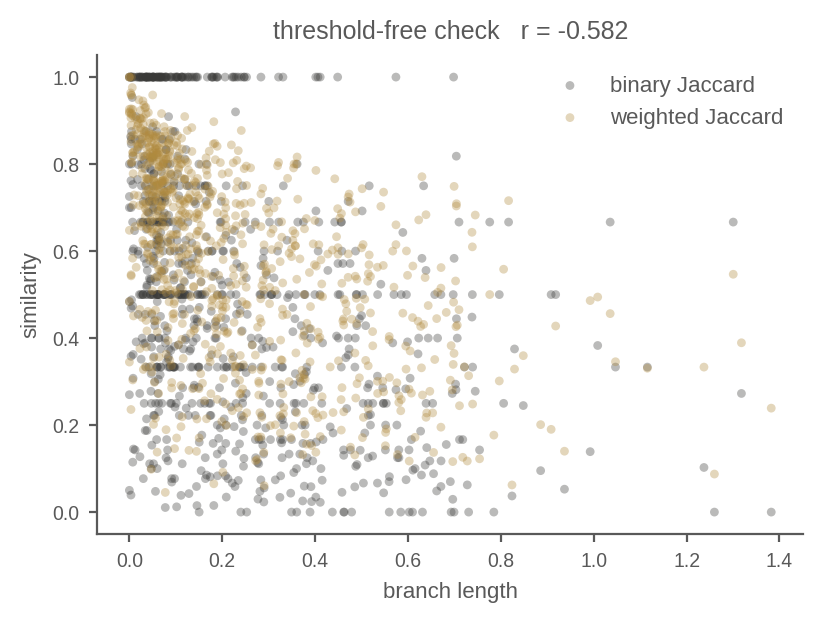

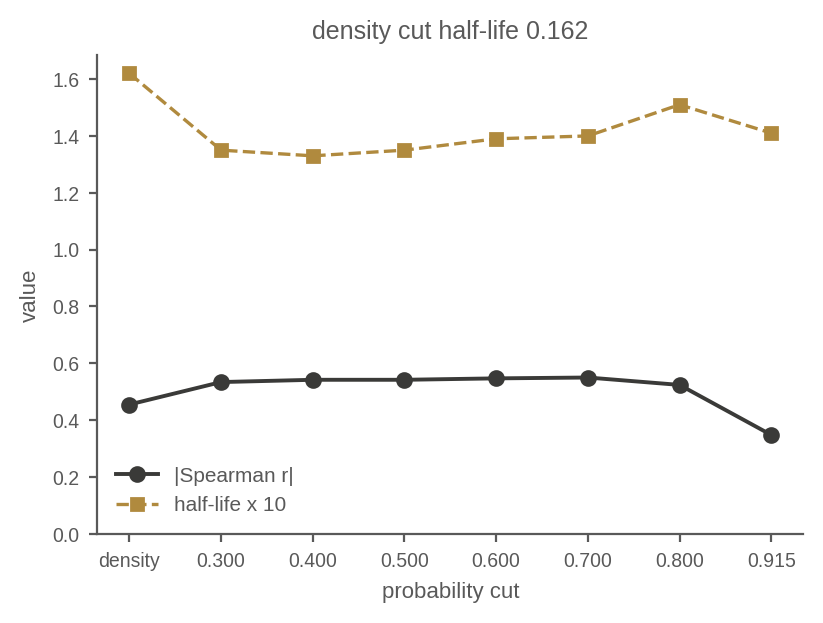

In [7]:
figures, axes = zip(*[plt.subplots(figsize=FIGSIZE, layout="constrained") for _ in range(2)])
ax = axes[0]
ax.scatter(edges.branch_len, edges.similarity, s=10, alpha=0.35,
           color="#3a3a38", edgecolor="none", label="binary Jaccard")
ax.scatter(edges.branch_len, edges.weighted, s=10, alpha=0.35,
           color="#b08a3e", edgecolor="none", label="weighted Jaccard")
ax.set_xlabel("branch length"); ax.set_ylabel("similarity")
ax.legend(frameon=False, fontsize=8)
ax.set_title(f"threshold-free check   r = {rw:+.3f}", fontsize=9)

ax = axes[1]
ax.plot(sweep.cut, -sweep.spearman, "o-", color="#3a3a38", lw=1.4, ms=5, label="|Spearman r|")
ax.plot(sweep.cut, sweep.half_life * 10, "s--", color="#b08a3e", lw=1.2, ms=4,
        label="half-life x 10")
ax.set_xlabel("probability cut"); ax.set_ylabel("value")
ax.set_ylim(0, None); ax.legend(frameon=False, fontsize=7.5)
density_row = sweep[sweep.cut == "density"].iloc[0]
ax.set_title(f"density cut half-life {density_row.half_life:.3f}", fontsize=9)
save_fig(figures[0], "threshold_check_similarity"); save_fig(figures[1], "threshold_check_sweep"); plt.show()